<div style="text-align:right">
<img src="imgs/logo-curso.jpg" width="30%" style="max-width:100%; padding-right:20px;">
</div>

**Fundamentos de la Inteligencia Artificial y Programación de APIs para LLMs**

# **01. Funcionamiento de una neurona**

## **1. Inspiración biológica**

Una neurona biológica es un tipo de célula que recibe señales procedentes de otras neuronas, las integra y puede transmitir nuevas señales a otras neuronas. La interconexión de millones de estas neuronas permite que los animales, incluidos los humanos, perciban, aprendan y tomen decisiones. Las redes neuronales artificiales (RNA) constituyen un paradigma de computación inspirado en estas neuronas biológicas y su interconexión.

De forma muy simplificada, las dendritas (en las neuronas biológicas) reciben señales que llegan al soma de la neurona. Si la señal es suficientemente fuerte, el soma genera una señal de salida que viaja por el axón hacia otras neuronas. La transmisión real incluye procesos electroquímicos mucho más complejos en los que no vamos a profundizar. Una neurona artificial no reproduce exactamente todos esos procesos: es una función matemática que sigue ese mecanismo natural inspirador.

En la figura siguiente podemos ver esquemáticamente una neurona biológica. Vemos las dendritas (entrada), el soma (procesamiento) y el axón (salida). La señal de salida se transmite a otras neuronas mediante conexiones sinápticas.

<div style="text-align:center">
<img src="imgs/neurona.jpg" alt="Una neurona biológica: dendritas, cuerpo celular y axón." width="650" style="max-width:100%;height:auto;display:block;margin-left:auto;margin-right:auto;">
Una neurona biológica: dendritas, cuerpo celular y axón.
</div>



## **2. La neurona artificial**

Siguiendo esta inspiración biológica, una neurona artificial recibe varias entradas, las combina y produce una salida. La combinación consiste en multiplicar cada entrada por un **peso** y sumar los resultados. Después, la neurona compara esa suma con un **umbral** para decidir si produce una señal de salida o no. Finalmente, esta salida podrá ser 1, si la suma alcanza o supera el umbral, o 0, si no lo hace. La neurona artificial es un modelo matemático que imita de manera muy simplificada el comportamiento de una neurona biológica.

Supongamos que tenemos dos entradas, $e_1$ y $e_2$. Primero calculamos:

$$z = w_1 e_1 + w_2 e_2.$$

Léelo así: «multiplica la primera entrada por su peso, multiplica la segunda por el suyo y suma». Después comparamos esa suma con un **umbral**, $\theta$ (se lee «theta»):

$$\text{salida}=\begin{cases}1,&z\geq\theta\\0,&z<\theta.\end{cases}$$

Ese símbolo $\geq$ significa «mayor o igual». Si alcanzamos o superamos el umbral, la neurona devuelve 1; si no, devuelve 0. Esta regla se llama **función de activación de escalón**. Los números 0 y 1 representan cada una de las dos posibles decisiones.

Por ejemplo, con entradas 2 y 3, pesos 0.5 y 1, y umbral 4, obtenemos $0.5\times2+1\cdot3=4$. Como hemos llegado exactamente al umbral, la salida es 1. Si las entradas fueran 2 y 2, la suma sería $0.5\times2+1\cdot2=3$, que es menor que el umbral, así que la salida sería 0.

<div style="text-align:center">
<img src="imgs/model.svg" alt="Entradas ponderadas, suma, umbral y función de activación." width="600" style="max-width:100%;height:auto;display:block;margin-left:auto;margin-right:auto;">
La figura representa n posibles entradas, cada una de ellas es multiplicada por un peso y luego, todos estos resultados, se suman. En este caso, la función g(x) hace la comparación con el umbral para determinar la salida final de la neurona.
</div>



### **Mi primera neurona**

En el siguiente código definimos una función que implementa la neurona que acabamos de describir. La función recibe las entradas, los pesos y el umbral, y devuelve la salida de la neurona.

In [1]:
def neurona(e1, e2):
    w1 = 0.5
    w2 = 1
    umbral = 4
    suma = w1 * e1 + w2 * e2
    if suma >= umbral:
        salida = 1
    else:
        salida = 0

    return int(salida)

print(neurona(e1 = 2, e2 = 3))
print(neurona(e1 = 2, e2 = 2))

1
0


### **Comprueba que lo has entendido**

Con la neurona del ejemplo anterior, ¿qué salida obtendrías con entradas 1 y 2? Haz el cálculo a mano y luego comprueba tu respuesta ejecutando la celda de código anteriror.

<details><summary>Ver respuesta razonada</summary>

La suma sería $0.5\times1+1\cdot2=2.5$, que es menor que el umbral 4, así que la salida sería 0.

</details>

## **3. Vectores de características**

De lo que hemos visto hasta ahora, podemos deducir que la neurona es capaz de tomar decisiones a partir de varias entradas. Pero aún no hemos dicho qué representan esas entradas. En la práctica, cada entrada puede ser una **característica** de un objeto que queremos clasificar. Por ejemplo, si queremos clasificar frutas, las características podrían ser el color, el tamaño, el peso, etc. Cada característica se representa mediante un número.

La tareas de **clasificación** consiste en asignar un objeto a una categoría entre varias posibles. Podemos clasificar mensajes como relevantes o irrelevantes, frutas como aptas o no aptas para la venta, móviles como de gama alta o baja, etc. Para que un programa trabaje con esos objetos, necesitamos representar alguna información sobre ellos mediante números.

Supongamos que queremos clasificar móviles en móviles de gama alta y gama baja. Podríamos pensar en características como el tamaño de la pantalla, cantidad de memoria, el tipo de procesador, etc. para decidir si un móvil es de gama alta o baja. En este caso, utilizaremos dos características: megapíxeles de la cámara y gigabytes de memoria. Supongamos que tenemos tres móviles, A, B y C, con las siguientes características:

- Móvil A: 10 megapíxeles de cámara y 64 gigabytes de memoria.
- Móvil B: 16 megapíxeles de cámara y 256 gigabytes de memoria.
- Móvil C: 8 megapíxeles de cámara y 32 gigabytes de memoria.

Si representamos cada móvil mediante una lista ordenada de sus características, obtenemos lo que llamamos **vector de características**. De esta forma, el móvil A tendrá como vector de características $(10,64)$, el móvil B tendrá $(16,256)$ y el móvil C tendrá $(8,32)$.

En términos generales, si tenemos un objeto con $n$ características, podemos representarlo mediante un vector de características de la forma:

$$\vec e=(e_1,e_2,\ldots,e_n).$$

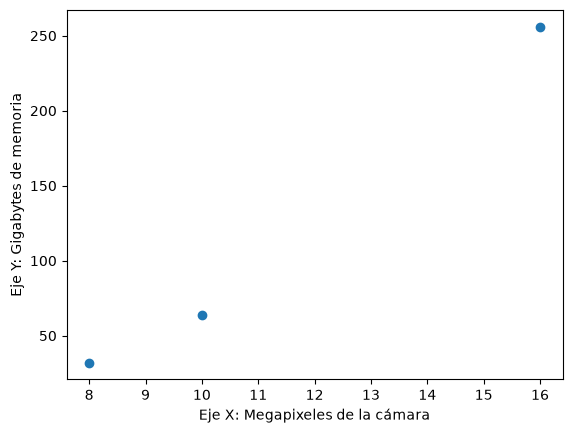

In [2]:
import numpy as np 
from matplotlib import pyplot as plt 

features = [[10,16,8], # megapixeles de las cámaras
            [64,256,32] # tamaño en gigabytes de las memorias
           ]

plt.scatter(features[0], features[1])

plt.xlabel("Eje X: Megapixeles de la cámara")
plt.ylabel("Eje Y: Gigabytes de memoria");
 
plt.show()

## **4. Clasificación lineal: separar con una recta**

Ahora que ya sabemos lo que es un vector de características, podemos representar cada objeto como un punto en el plano. La primera coordenada es la primera característica y la segunda coordenada es la segunda característica. Ten en cuenta que, en general, los vectores de características pueden tener más de dos componentes. Si tuviéramos tres características (megapíxeles de la cámara, gigabytes de memoria y velocidad del procesador), necesitaríamos un espacio tridimensional para representarlos, y así sucesivamente. Pero para poder representarlos gráficamente nos limitaremos a dos dimensiones. 

Imagina ahora dos grupos de puntos, como en la figura siguiente, estos pueden representar cualquier cosa (móviles u otros objetos). Son de dos tipos, clases o categorías diferentes. Representamos con color azul los que pertenecen a una clase y con color rojo los que pertenecen a la otra clase. Si fueran móviles, por ejemplo, los rojos podrían ser de gama alta ya que tienen los valores de las características más altos, mientras que los azules podrían ser de gama baja.

Si podemos trazar una recta que deje todos los azules en un lado y todos los rojos en el otro, decimos que las clases son **linealmente separables**.

<div style="text-align:center">
<img src="imgs/set2.png" alt="Una recta separa los ejemplos de las dos clases." width="450" style="max-width:100%;height:auto;display:block;margin-left:auto;margin-right:auto;">
</div>

Fíjate en la siguiente figura. En este caso, no podemos trazar una recta que separe perfectamente ambos conjuntos.

<div style="text-align:center">
<img src="imgs/set3.png" alt="Un conjunto que una única recta no puede separar perfectamente." width="450" style="max-width:100%;height:auto;display:block;margin-left:auto;margin-right:auto;">
</div>

## **5. Terminología**

Ahora que ya tenemos claro lo que significa "clasificar", definamos algo de terminología. Cada uno de los puntos u objetos a clasificar se denomina ejemplo. El conjunto de todos los ejemplos se denomina conjunto de datos (aunque te lo vas encontrar en muchos textos en español con el término anglosajón *dataset*). Todos estos ejemplos pertenecerán a un grupo u otro. A cada uno de estos dos grupos lo denominamos clase o categoría.

| Término | En el ejemplo de los móviles |
|---|---|
| Ejemplo | Un móvil concreto |
| Característica (*feature*) | Megapíxeles o memoria |
| Vector de características | EL vector `(10, 64)` |
| Clase | Una de las dos categorías |
| Etiqueta | Gama alta o gama baja |
| Conjunto de datos o dataset | La colección de móviles y sus etiquetas |


## **6. La neurona artificial como clasificador lineal**

Una neurona artificial va a ser el instrumento que nos permitirá clasificar ejemplos de dos clases diferentes. Vamos a ver cómo funciona.

En la siguiente figura, se muestran los puntos "a", "b" y "c" que pertenecen a una clase y "d" y "e" a otra. Observa que "a" está exactamente sobre la recta.

<div style="text-align:center">
<img src="imgs/ejemplo1.png" alt="La recta y = x/2 + 1 y el semiplano de activación." width="450" style="max-width:100%;height:auto;display:block;margin-left:auto;margin-right:auto;">
</div>

Veamos esto desde un punto de vista matemático y entenderemos cómo se relaciona con la neurona. Si hacemos unos cálculos básicos, la recta de la figura anterior tiene ecuación:

$$y=\frac12x+1.$$

Esta ecuación es el lugar geométrico de todos los puntos que satisfacen la igualdad, es decir, solo los puntos sobre la línea. Pero si queremos hallar el lugar geométrico de todos los puntos que están por encima de la recta, necesitamos una **inecuación**.

$$y\geq\frac12x+1.$$

Esto nos da el semiplano por encima de la recta. Todos los puntos que satisfacen esta inecuación se encuentran en la zona azulada de la figura. Vamos a pasar el término con $x$ al lado izquierdo de la inecuación.

$$-\frac12x+1y\geq1.$$

Ahora, si hacemos un simple cambio de nombres de variables y llamamos $e_1$ a $x$ y $e_2$ a $y$ y hacemos corresponder a $-\frac12$ con $w_1$, a $1$ con $w_2$ y $1$ con $\theta$ nos damos cuenta de que una neurona artificial no es, ni más ni menos, que una forma de escribir la misma condición. No hay un salto mágico entre la inecuación y la neurona: son dos formas de llegar a lo mismo.

$$ w_1e_1 + w_2e_2 \geq \theta \rightarrow \Sigma_{i=1}^n w_i e_i \geq \theta$$

En el siguiente código hemos implementado esta neurona. En a=(2,2), el resulado es 1 y la neurona se activa por la igualdad. En b=(1,3), vale 2.5 y también se activa. En d=(3,1), vale −0.5 y no se activa.

In [3]:
def neurona(e1, e2):
    w1 = -1/2
    w2 = 1
    umbral = 1
    suma = w1 * e1 + w2 * e2
    if suma >= umbral:
        salida = 1
    else:
        salida = 0
    return int(salida)

puntos = {"a": (2, 2), "b": (1, 3), "c": (2, 4),
          "d": (3, 1), "e": (5, 2)}

for nombre, (x, y) in puntos.items():
    print(nombre, (x, y), "→", neurona(x, y))

a (2, 2) → 1
b (1, 3) → 1
c (2, 4) → 1
d (3, 1) → 0
e (5, 2) → 0


### **Comprueba que lo has entendido**

1. Calcula sin ejecutar el código la clase de (4,3). ¿Está por encima, por debajo o sobre la recta?
2. Cambia el umbral a 2. ¿Sube o baja la frontera?
3. Explica por qué dos pesos negativos no harían que una neurona dejase de funcionar.
4. Dibuja un conjunto con dos colores que una recta no pueda separar.

<details><summary>Soluciones y orientación</summary>

1. −0.5·4 + 3 = 1: está sobre la frontera y devuelve 1.
2. La nueva frontera es y = 0.5x + 2: sube. A un mismo x le pedimos un y mayor para activar la neurona.
3. Los pesos negativos restan a la suma; son valores válidos. Solo cambian la región donde la neurona se activa.
4. Un ejemplo son cuatro vértices de un cuadrado con colores alternados: un color ocupa una diagonal y el otro la diagonal restante. Lo retomaremos al hablar de redes.

</details>

[Notebook 2 →](02-sigmoide-y-gradiente.ipynb)